# Exploratory data analysis: Yambda-50M

Yambda-50M is a public log of Yandex Music activity: listens with the share of each track played, plus likes and dislikes, from 10,000 users over about 300 days. This notebook describes the properties of the data that shape the recommender built on top of it: heavy-tailed users and tracks, frequent re-listening, the split between organic and recommendation-driven plays, and the temporal split used for validation and testing.

All aggregation runs as DuckDB SQL over the parquet files; only small result tables are loaded into pandas.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path('..')
os.environ.setdefault('DATA_DIR', str(ROOT / 'data'))
sys.path.insert(0, str(ROOT / 'src'))

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from yrec.data import RAW, PROC, DAY, A_END, B_START, B_END, C_START

FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b4b2ab', '#52514e'
plt.rcParams.update({
    'figure.figsize': (8, 4), 'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': INK,
    'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'axes.titleweight': 'bold',
    'axes.titlesize': 12, 'axes.titlelocation': 'left', 'axes.grid': True, 'grid.color': '#e6e5e1',
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'axes.grid.axis': 'y', 'legend.frameon': False, 'font.size': 10,
})
def save(fig, name):
    fig.savefig(FIG / f'{name}.png'); plt.show()

con = duckdb.connect()
con.execute(f"""
CREATE VIEW listens AS SELECT * FROM '{RAW}/listens.parquet';
CREATE VIEW likes    AS SELECT * FROM '{RAW}/likes.parquet';
CREATE VIEW dislikes AS SELECT * FROM '{RAW}/dislikes.parquet';
""")
q = lambda sql: con.sql(sql).df()

## 1. Dataset overview

Size of the raw event logs and the time span they cover.

In [2]:
ov = q("""
SELECT (SELECT count(*) FROM read_parquet('PROC_USERS'))         AS users,
       (SELECT count(DISTINCT uid) FROM listens)                 AS users_with_listens,
       (SELECT count(*) FROM read_parquet('PROC_ITEMS'))         AS tracks,
       (SELECT count(*) FROM listens)                            AS listens,
       (SELECT count(*) FROM likes)                              AS likes,
       (SELECT count(*) FROM dislikes)                           AS dislikes,
       (SELECT (max(timestamp) - min(timestamp)) / 86400.0 FROM listens) AS span_days
""".replace('PROC_ITEMS', str(PROC / 'items.parquet')).replace('PROC_USERS', str(PROC / 'users.parquet'))).T.rename(columns={0: 'value'})
display(ov.style.format('{:,.0f}'))
print(f"{ov.value['listens'] / ov.value['users_with_listens']:,.0f} listens per listening user on average; "
      f"explicit reactions (likes + dislikes) amount to {(ov.value['likes'] + ov.value['dislikes']) / ov.value['listens']:.1%} of listen volume.")

,value
users,"10,000"
users_with_listens,"9,238"
tracks,"934,057"
listens,"46,467,212"
likes,"881,456"
dislikes,"107,776"
span_days,301


5,030 listens per listening user on average; explicit reactions (likes + dislikes) amount to 2.1% of listen volume.


## 2. User history length

Number of listens per user over the full log. A log-spaced histogram shows the spread across orders of magnitude.

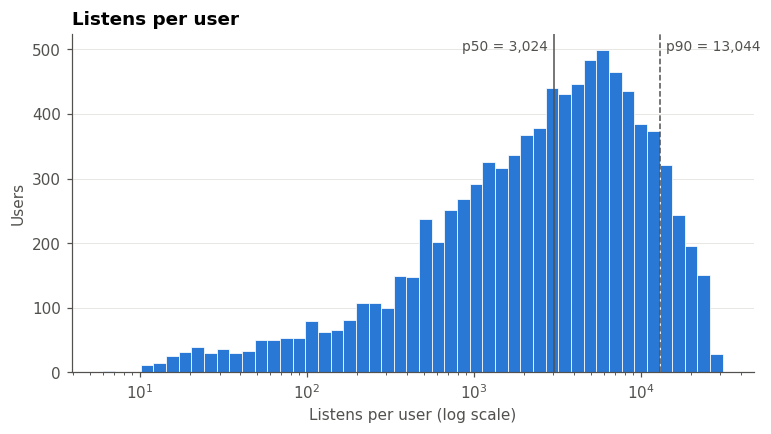

Median user: 3,024 listens; p10 = 258, p90 = 13,044; the top 10% of users account for 35.8% of all listens.


In [3]:
u = q('SELECT uid, count(*) AS n FROM listens GROUP BY uid')
fig, ax = plt.subplots()
bins = np.logspace(np.log10(u.n.min()), np.log10(u.n.max()) + 0.05, 50)
ax.hist(u.n, bins=bins, color=BLUE, edgecolor='white', linewidth=0.5)
ax.set_xscale('log')
for p, ls, side in [(0.5, '-', 'right'), (0.9, '--', 'left')]:
    v = u.n.quantile(p); ax.axvline(v, color=INK, ls=ls, lw=1)
    ax.annotate(f'p{int(p*100)} = {v:,.0f}', (v, ax.get_ylim()[1] * 0.95), xytext=(-4 if side == 'right' else 4, 0),
                textcoords='offset points', color=INK, fontsize=9, ha=side)
ax.set(xlabel='Listens per user (log scale)', ylabel='Users', title='Listens per user')
save(fig, '02_user_history')
print(f'Median user: {u.n.median():,.0f} listens; p10 = {u.n.quantile(.1):,.0f}, p90 = {u.n.quantile(.9):,.0f}; '
      f'the top 10% of users account for {u.n.nlargest(len(u) // 10).sum() / u.n.sum():.1%} of all listens.')

## 3. Track popularity long tail

Listens per track, ranked from most to least popular. A straight-ish line on log-log axes is the usual power-law shape of music consumption.

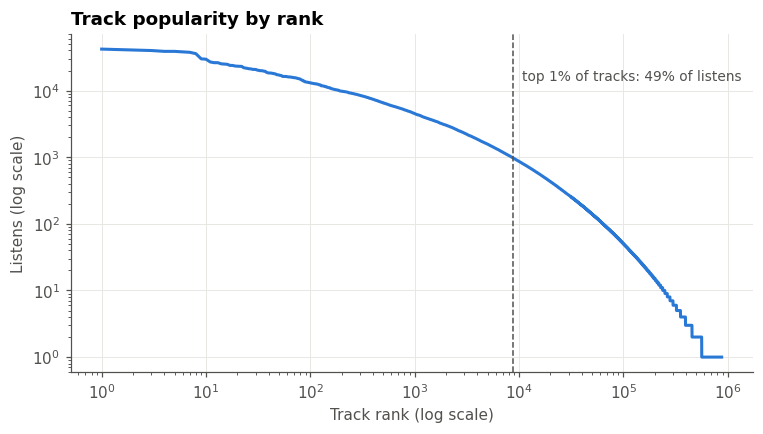

877,168 tracks were played at least once; the top 1% receive 49.2% of listens, and 63.2% of tracks have 5 listens or fewer.


In [4]:
pop = q('SELECT count(*) AS n FROM listens GROUP BY item_id ORDER BY n DESC').n.to_numpy()
rank = np.arange(1, len(pop) + 1)
top1 = pop[: max(1, len(pop) // 100)].sum() / pop.sum()
fig, ax = plt.subplots()
ax.loglog(rank, pop, color=BLUE, lw=2); ax.grid(True, axis='both')
ax.axvline(len(pop) // 100, color=INK, ls='--', lw=1)
ax.annotate(f'top 1% of tracks: {top1:.0%} of listens', (len(pop) // 100, pop[0] / 3), xytext=(6, 0),
            textcoords='offset points', color=INK, fontsize=9)
ax.set(xlabel='Track rank (log scale)', ylabel='Listens (log scale)', title='Track popularity by rank')
save(fig, '03_popularity_long_tail')
print(f'{len(pop):,} tracks were played at least once; the top 1% receive {top1:.1%} of listens, '
      f'and {(pop <= 5).mean():.1%} of tracks have 5 listens or fewer.')

## 4. Played ratio and Listen+

`played_ratio_pct` is the share of the track that was played (values above 100 are replays within a session and are clipped here). Following the Yambda paper, a listen with at least 50% played counts as a positive "Listen+" event.

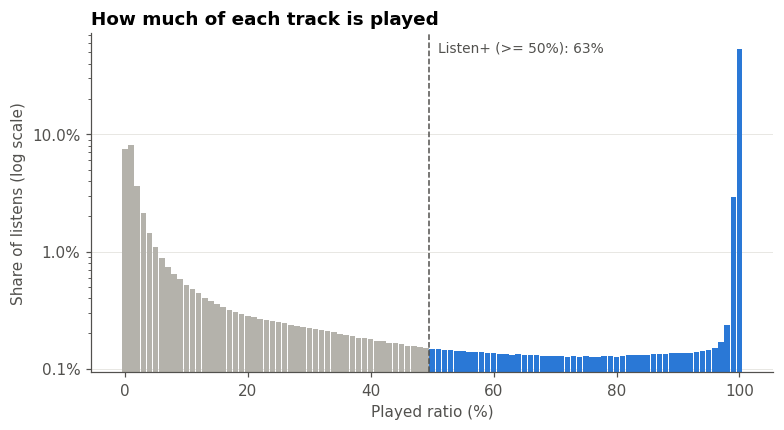

63.4% of listens are Listen+; 53.7% play the whole track and 26.6% are skipped within the first 10%.


In [5]:
pr = q('SELECT least(played_ratio_pct, 100) AS r, count(*) AS n FROM listens GROUP BY 1 ORDER BY 1')
lp_share = pr.loc[pr.r >= 50, 'n'].sum() / pr.n.sum()
fig, ax = plt.subplots()
ax.bar(pr.r, pr.n / pr.n.sum(), width=0.9, color=np.where(pr.r >= 50, BLUE, GREY))
ax.axvline(49.5, color=INK, ls='--', lw=1)
ax.text(51, ax.get_ylim()[1] * 0.9, f'Listen+ (>= 50%): {lp_share:.0%}', color=INK, fontsize=9)
ax.set_yscale('log'); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set(xlabel='Played ratio (%)', ylabel='Share of listens (log scale)', title='How much of each track is played')
save(fig, '04_played_ratio')
print(f'{lp_share:.1%} of listens are Listen+; {pr.loc[pr.r == 100, "n"].sum() / pr.n.sum():.1%} play the whole track '
      f'and {pr.loc[pr.r < 10, "n"].sum() / pr.n.sum():.1%} are skipped within the first 10%.')

## 5. Repeat consumption

A listen is a re-listen when the same user played the same track earlier. The test-day labels (`tgt_AB`: the day after the final cutoff) are then split into tracks the user had never played before the cutoff (`is_new`) and tracks already in the user's history. A model that only replays history can score well on the second group without discovering anything, so the two are evaluated separately.

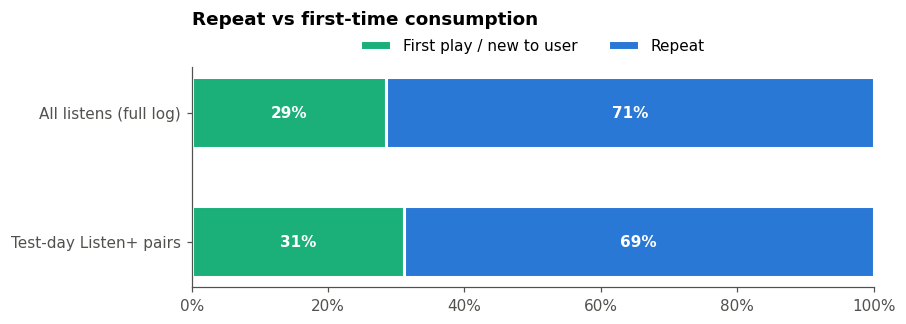

71.4% of all listens are re-listens; of the 127,834 test-day Listen+ (user, track) pairs, 31.1% are new to the user and 68.9% are repeats.


In [6]:
rep = con.sql('SELECT 1 - count(DISTINCT (uid, item_id)) / count(*) FROM listens').fetchone()[0]
tg = q(f"SELECT avg(is_new::INT) AS new, count(*) AS n FROM '{PROC}/tgt_AB.parquet' WHERE lp")
new = tg.new[0]
fig, ax = plt.subplots(figsize=(8, 2.6))
rows = [('All listens (full log)', 1 - rep, rep), ('Test-day Listen+ pairs', new, 1 - new)]
for i, (lbl, first, again) in enumerate(rows):
    ax.barh(i, first, color=AQUA, height=0.55, edgecolor='white', linewidth=2, label='First play / new to user' if i == 0 else None)
    ax.barh(i, again, left=first, color=BLUE, height=0.55, edgecolor='white', linewidth=2, label='Repeat' if i == 0 else None)
    ax.text(first / 2, i, f'{first:.0%}', ha='center', va='center', color='white', fontweight='bold')
    ax.text(first + again / 2, i, f'{again:.0%}', ha='center', va='center', color='white', fontweight='bold')
ax.set_yticks(range(2), [r[0] for r in rows]); ax.invert_yaxis(); ax.grid(False)
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xlim(0, 1)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.set_title('Repeat vs first-time consumption', pad=28)
save(fig, '05_repeat_consumption')
print(f'{rep:.1%} of all listens are re-listens; of the {tg.n[0]:,} test-day Listen+ (user, track) pairs, '
      f'{new:.1%} are new to the user and {1 - new:.1%} are repeats.')

## 6. Organic vs recommendation-driven listens

`is_organic = 1` marks listens the user chose directly (search, library, album); `0` marks listens served by the platform's own recommendations. The skip rate is the share of listens below the Listen+ threshold.

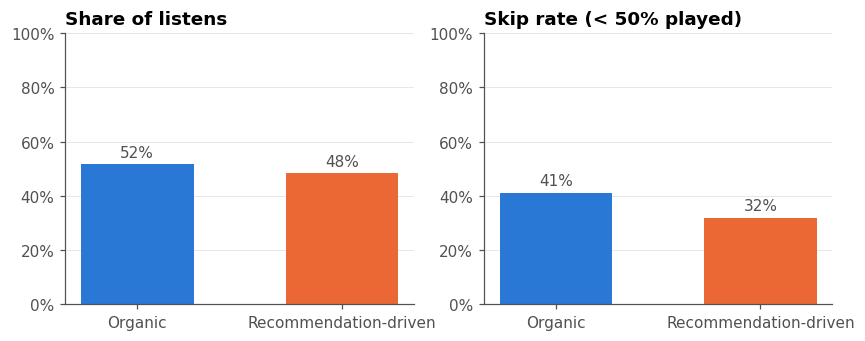

48.3% of listens are recommendation-driven, with a skip rate of 31.8% versus 41.2% for organic listens.


In [7]:
org = q("""
SELECT CASE WHEN is_organic = 1 THEN 'Organic' ELSE 'Recommendation-driven' END AS source,
       count(*) AS n, avg((played_ratio_pct < 50)::INT) AS skip_rate
FROM listens GROUP BY 1 ORDER BY 1""")
org['share'] = org.n / org.n.sum()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, col, title in [(axes[0], 'share', 'Share of listens'), (axes[1], 'skip_rate', 'Skip rate (< 50% played)')]:
    bars = ax.bar(org.source, org[col], color=[BLUE, ORANGE], width=0.55)
    ax.bar_label(bars, labels=[f'{v:.0%}' for v in org[col]], padding=3, color=INK)
    ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 1); ax.set_title(title)
save(fig, '06_organic_vs_reco')
o, r = org.set_index('source').loc['Organic'], org.set_index('source').loc['Recommendation-driven']
print(f'{r.share:.1%} of listens are recommendation-driven, with a skip rate of {r.skip_rate:.1%} '
      f'versus {o.skip_rate:.1%} for organic listens.')

## 7. Cold-start tracks

A test-day Listen+ target is cold when its track has no listens at all before the final cutoff (it is absent from `ifeat_AB`). Collaborative signals cannot reach such tracks; only content features (for example audio embeddings) can.

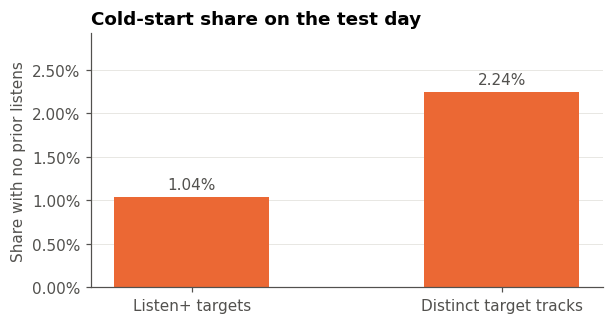

1.04% of test-day Listen+ targets (1,329 pairs, 2.24% of distinct target tracks) point at tracks never played before the cutoff.


In [8]:
cold = q(f"""
SELECT f.item_idx IS NULL AS cold, count(*) AS n, count(DISTINCT t.item_idx) AS tracks
FROM '{PROC}/tgt_AB.parquet' t LEFT JOIN '{PROC}/ifeat_AB.parquet' f USING (item_idx)
WHERE t.lp GROUP BY 1 ORDER BY 1""").set_index('cold')
share = cold.n.get(True, 0) / cold.n.sum()
tshare = cold.tracks.get(True, 0) / cold.tracks.sum()
fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(['Listen+ targets', 'Distinct target tracks'], [share, tshare], color=ORANGE, width=0.5)
ax.bar_label(bars, labels=[f'{v:.2%}' for v in (share, tshare)], padding=3, color=INK)
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, max(share, tshare) * 1.3 + 1e-9)
ax.set(ylabel='Share with no prior listens', title='Cold-start share on the test day')
save(fig, '07_cold_start')
print(f'{share:.2%} of test-day Listen+ targets ({cold.n.get(True, 0):,} pairs, {tshare:.2%} of distinct target tracks) '
      f'point at tracks never played before the cutoff.')

## 8. Activity over time

Daily listen volume across the log. The dashed lines mark the evaluation split from `yrec.data`: history window A ends, the validation day B follows (ranker training labels), and the final day C is the test day. Each boundary includes a 30-minute gap.

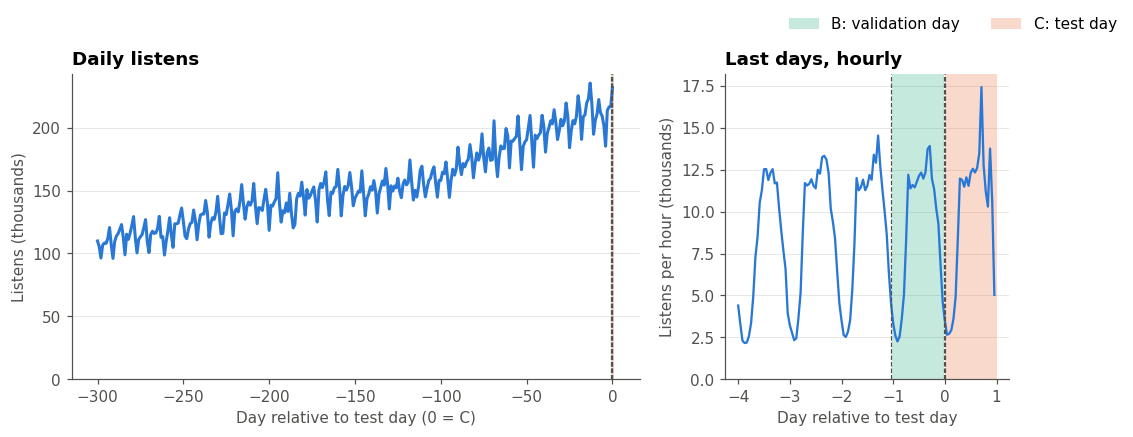

Mean 154,376 listens per day over 301 days; daily volume grows from 106,686 (first week) to 210,815 (last week), x1.98. Test day C: 232,049 listens.


In [9]:
# Days are aligned to the end of the log so that day 0 is exactly the test day C
# (the few events stamped exactly at the end of the log are folded into it).
d = q(f'SELECT least(floor((timestamp::BIGINT - {C_START}) / {DAY}), 0)::INT AS day, count(*) AS n FROM listens GROUP BY 1 ORDER BY 1')
h = q(f'SELECT least(floor((timestamp::BIGINT - {C_START}) / 3600), 23)::INT AS hour, count(*) AS n FROM listens '
      f'WHERE timestamp >= {C_START - 4 * DAY} GROUP BY 1 ORDER BY 1')
fig, (ax, az) = plt.subplots(1, 2, figsize=(11, 3.6), width_ratios=[2, 1])
ax.plot(d.day, d.n / 1e3, color=BLUE, lw=2)
ax.set(xlabel='Day relative to test day (0 = C)', ylabel='Listens (thousands)', title='Daily listens'); ax.set_ylim(0)
az.plot(h.hour / 24, h.n / 1e3, color=BLUE, lw=1.5)
for a in (ax, az):
    a.axvspan((B_START - C_START) / DAY, (B_END - C_START) / DAY, color=AQUA, alpha=0.25, lw=0, label='B: validation day')
    a.axvspan(0, 1, color=ORANGE, alpha=0.25, lw=0, label='C: test day')
    for t in (A_END, B_END, C_START):
        a.axvline((t - C_START) / DAY, color=INK, ls='--', lw=0.8)
az.set(xlabel='Day relative to test day', ylabel='Listens per hour (thousands)', title='Last days, hourly'); az.set_ylim(0)
fig.legend(*az.get_legend_handles_labels(), loc='upper right', ncol=2, bbox_to_anchor=(1, 1.06))
save(fig, '08_daily_listens')
first7, last7 = d.n.iloc[:7].mean(), d.n.iloc[-7:].mean()
print(f'Mean {d.n.mean():,.0f} listens per day over {len(d)} days; daily volume grows from {first7:,.0f} '
      f'(first week) to {last7:,.0f} (last week), x{last7 / first7:.2f}. Test day C: {d.n.iloc[-1]:,} listens.')

## 9. Audio embeddings

Yambda ships a 128-dimensional audio embedding per track. A 2-D PCA projection of a random sample shows whether the space carries structure related to popularity and artist identity. The section runs only when `data/proc/audio.npy` (aligned to `items.idx`) is present.

In [10]:
audio_path = PROC / 'audio.npy'
if not audio_path.exists():
    print(f'{audio_path} not found; audio section skipped.')
else:
    from sklearn.decomposition import PCA
    emb = np.load(audio_path, mmap_mode='r')
    items = pd.read_parquet(PROC / 'items.parquet', columns=['idx', 'artist_idx'])
    items['has'] = np.abs(emb).sum(1) > 0
    n_pop = q(f"SELECT item_idx AS idx, i_n_listen FROM '{PROC}/ifeat_AB.parquet'")
    items = items.merge(n_pop, on='idx', how='left').fillna({'i_n_listen': 0})
    cand = items[items.has]
    s = cand.sample(min(50_000, len(cand)), random_state=0)
    known = cand[cand.artist_idx < items.artist_idx.max()]  # last index = unknown artist
    top = known.groupby('artist_idx').i_n_listen.sum().nlargest(3).index
    art = cand[cand.artist_idx.isin(top)]
    art = art.groupby('artist_idx', group_keys=False).apply(lambda g: g.sample(min(len(g), 2000), random_state=0))
    pca = PCA(2, random_state=0).fit(np.asarray(emb[s.idx], dtype=np.float32))
    xy, axy = pca.transform(np.asarray(emb[s.idx], np.float32)), pca.transform(np.asarray(emb[art.idx], np.float32))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
    o = np.argsort(s.i_n_listen.to_numpy())
    sc = axes[0].scatter(xy[o, 0], xy[o, 1], c=np.log10(1 + s.i_n_listen.to_numpy()[o]), cmap='Blues', vmin=-1, s=3, lw=0)
    fig.colorbar(sc, ax=axes[0], label='log10(1 + listens before test cutoff)')
    axes[0].set_title('Coloured by track popularity')
    axes[1].scatter(xy[:, 0], xy[:, 1], color='#e6e5e1', s=3, lw=0)
    for c, a in zip([BLUE, ORANGE, AQUA], top):
        m = art.artist_idx.to_numpy() == a
        axes[1].scatter(axy[m, 0], axy[m, 1], color=c, s=10, lw=0.4, edgecolor='white', label=f'artist {a} ({m.sum()} tracks)')
    axes[1].legend(loc='best', markerscale=2); axes[1].set_title('Three most-played artists')
    for ax in axes: ax.set(xlabel='PC 1', ylabel='PC 2'); ax.grid(False)
    save(fig, '09_audio_pca')
    corr = np.corrcoef(xy[:, 0], np.log1p(s.i_n_listen))[0, 1]
    spread = np.mean([axy[art.artist_idx.to_numpy() == a].std(0).mean() for a in top]) / xy.std(0).mean()
    print(f'{items.has.mean():.1%} of tracks have audio; the first two PCs explain {pca.explained_variance_ratio_.sum():.1%} '
          f'of variance; corr(PC1, log popularity) = {corr:.2f}; top-artist spread is {spread:.2f}x the global spread.')

../data/proc/audio.npy not found; audio section skipped.


## Summary

- Users and tracks are both heavy-tailed, so popularity is a strong baseline and per-user models must handle very short and very long histories.
- Most listens are repeats, and most test-day Listen+ pairs are tracks already in the user's history. Metrics are therefore reported on all Listen+ targets and separately on the discovery subset (`is_new`).
- Cold tracks are a small share of test-day targets, which bounds how much content-only signals can add on this split.